# Notebook 06: Image-Based Visual Recommendation Engine
## AI Fashion Recommendation System

### 1. Conceptual Foundation
Fashion is inherently visual. While metadata (e.g., "blue shirt", "cotton dress") captures categorical taxonomy, it fails to encode fine-grained visual characteristics such as:
- **Silhouettes & Cuts**: V-neck vs. crew neck, oversized vs. slim fit, A-line vs. pencil skirt.
- **Surface Patterns**: Houndstooth, pinstripes, floral motifs, tie-dye.
- **Fabric Texture & Drape**: Knitwear ribbing, denim wash, satin sheen, distressed finishes.

### 2. Pretrained MobileNetV2 Vision Backbone:
- We employ a lightweight, high-efficiency **MobileNetV2** backbone pretrained on ImageNet.
- Truncating the network before the final 1,000-class classification head yields a **1280-dimensional latent visual embedding** from the Global Average Pooling layer.
- **L2 Normalization**: Each vector is normalized:
  $$\hat{v} = \frac{v}{\|v\|_2}$$
- Cosine similarity between image $i$ and image $j$ reduces to their inner product:
  $$\text{VisualSim}(i, j) = \hat{v}_i \cdot \hat{v}_j^T$$

### 3. Notebook Objectives:
- Extract and normalize 1280-d image embeddings for active catalog items using CPU PyTorch.
- Implement an instant visual nearest-neighbor search engine.
- Visually evaluate recommendations on diverse garments (stripes, patterns, textures).
- Directly compare visual recommendations with text-based recommendations to demonstrate their complementary nature.
- Benchmark retrieval latency (target: sub-10ms).
- Persist visual embeddings in `artifacts/embeddings/` for hybrid recommendation and backend API serving.


In [1]:
import os
import sys
import time
import json
from pathlib import Path

import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

print("Vision Backbone libraries loaded successfully!")
print(f"PyTorch version: {torch.__version__} (Device: CPU)")


Vision Backbone libraries loaded successfully!
PyTorch version: 2.15.0+cpu (Device: CPU)


## Section 1: Load Pretrained Vision Backbone & Image Transformations

### What we are doing:
We load MobileNetV2 with default ImageNet weights and configure the standard inference preprocessing pipeline:
- Resize to 256x256.
- Center crop to 224x224.
- Convert to Tensor and normalize using ImageNet channel mean `[0.485, 0.456, 0.406]` and standard deviation `[0.229, 0.224, 0.225]`.


In [2]:
PROJECT_ROOT = Path(".").resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_EMBEDDINGS_DIR = PROJECT_ROOT / "artifacts" / "embeddings"
ARTIFACTS_META_DIR = PROJECT_ROOT / "artifacts" / "metadata"

ARTIFACTS_EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_META_DIR.mkdir(parents=True, exist_ok=True)

# Standard evaluation transform
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load MobileNetV2 feature extractor (truncate classifier)
weights = MobileNet_V2_Weights.DEFAULT
base_model = mobilenet_v2(weights=weights)
base_model.eval()

# Feature extractor outputs 1280-d vector from global average pooling
feature_extractor = base_model.features
pool = torch.nn.AdaptiveAvgPool2d((1, 1))

print("MobileNetV2 feature extractor initialized successfully!")


MobileNetV2 feature extractor initialized successfully!


## Section 2: Extracting Visual Feature Embeddings

### What we are doing:
We select active catalog items with verified on-disk images. For each image:
1. Open and transform the image tensor.
2. Pass through the convolutional feature extractor with `torch.no_grad()`.
3. Pool and flatten into a 1280-d vector.
4. Apply L2 normalization.
5. Save the resulting embedding matrix `(N, 1280)` and corresponding `article_id` list to `artifacts/embeddings/`.


In [3]:
# Load cleaned articles
df_articles = pd.read_parquet(DATA_PROCESSED_DIR / "hm_articles_cleaned.parquet")
active_items = df_articles[df_articles["has_image"] == 1].copy()

EMBED_FILE = ARTIFACTS_EMBEDDINGS_DIR / "hm_image_embeddings.npy"
AIDS_FILE = ARTIFACTS_EMBEDDINGS_DIR / "hm_image_aids.json"

if EMBED_FILE.exists() and AIDS_FILE.exists():
    print("Loading precomputed visual embeddings from disk...")
    visual_embeddings = np.load(EMBED_FILE)
    with open(AIDS_FILE, "r", encoding="utf-8") as f:
        valid_aids = json.load(f)
    print(f"Loaded {len(visual_embeddings):,} embeddings from: {EMBED_FILE}")
else:
    np.random.seed(42)
    sample_size = 3000
    selected_indices = []
    for cat in active_items["standard_category"].unique():
        cat_items = active_items[active_items["standard_category"] == cat]
        n_sample = min(len(cat_items), sample_size // len(active_items["standard_category"].unique()))
        selected_indices.extend(np.random.choice(cat_items.index, size=n_sample, replace=False))

    df_embed_sample = active_items.loc[selected_indices].reset_index(drop=True)
    print(f"Extracting visual embeddings for {len(df_embed_sample):,} representative catalog items...")

    embeddings_list = []
    valid_aids = []

    t0 = time.time()
    with torch.no_grad():
        for idx, row in df_embed_sample.iterrows():
            img_path = PROJECT_ROOT / row["image_path"]
            try:
                with Image.open(img_path) as img:
                    tensor = transform(img.convert("RGB")).unsqueeze(0)
                    feat = pool(feature_extractor(tensor)).squeeze().numpy()
                    norm = np.linalg.norm(feat)
                    if norm > 0:
                        feat = feat / norm
                    embeddings_list.append(feat)
                    valid_aids.append(row["article_id"])
            except Exception as e:
                continue
                
            if (idx + 1) % 500 == 0:
                print(f"  Processed {idx + 1:,} / {len(df_embed_sample):,} images ({time.time()-t0:.1f}s)...")

    visual_embeddings = np.array(embeddings_list, dtype=np.float32)
    duration = time.time() - t0
    print(f"\nExtracted {len(visual_embeddings):,} visual embeddings in {duration:.2f}s!")

    np.save(EMBED_FILE, visual_embeddings)
    with open(AIDS_FILE, "w", encoding="utf-8") as f:
        json.dump(valid_aids, f)

print(f"Visual embedding matrix shape: {visual_embeddings.shape}")


Loading precomputed visual embeddings from disk...


Loaded 2,786 embeddings from: H:\datasets\artifacts\embeddings\hm_image_embeddings.npy
Visual embedding matrix shape: (2786, 1280)


## Section 3: Visual Similarity Search Engine

### What we are doing:
We implement the `VisualRecommender` class.
Given a query `article_id`:
- It retrieves the 1280-d normalized visual vector $v_{query}$.
- It computes dense dot product against all catalog visual embeddings:
  $$\text{scores} = \text{visual\_embeddings} \cdot v_{query}$$
- It extracts the top-$K$ most visually similar items.


In [4]:
class VisualRecommender:
    """Production Visual Nearest-Neighbor Search Engine using MobileNetV2 Embeddings."""
    
    def __init__(self, embeddings_matrix, aids_list, metadata_df):
        self.embeddings = embeddings_matrix # (N, 1280)
        self.aids = aids_list
        self.aid2idx = {aid: idx for idx, aid in enumerate(aids_list)}
        self.metadata = metadata_df.set_index("article_id").to_dict("index")
        
    def recommend(self, query_aid, top_k=5):
        if query_aid not in self.aid2idx:
            raise KeyError(f"Article '{query_aid}' not in visual embedding index.")
            
        q_idx = self.aid2idx[query_aid]
        q_vec = self.embeddings[q_idx] # (1280,)
        
        # Fast vector dot product
        scores = np.dot(self.embeddings, q_vec)
        scores[q_idx] = -1.0 # Exclude self
        
        top_indices = np.argsort(scores)[::-1][:top_k]
        
        results = []
        for rank, idx in enumerate(top_indices, 1):
            aid = self.aids[idx]
            meta = self.metadata[aid]
            results.append({
                "rank": rank,
                "article_id": aid,
                "prod_name": meta["prod_name"],
                "product_type_name": meta["product_type_name"],
                "product_group_name": meta["product_group_name"],
                "colour_group_name": meta["colour_group_name"],
                "standard_category": meta["standard_category"],
                "visual_similarity": round(float(scores[idx]), 4),
                "image_path": meta["image_path"]
            })
            
        return pd.DataFrame(results)

visual_engine = VisualRecommender(visual_embeddings, valid_aids, df_articles)
print("VisualRecommender engine initialized successfully!")


VisualRecommender engine initialized successfully!


## Section 4: Qualitative Visual Testing with Actual Photos

### What we are doing:
We test the visual recommender on items with distinct visual patterns and display the query photo alongside top-5 visually closest recommendations.


VISUAL QUERY: [0602733006] CHARLOTTE BOHO BLOUSE SS
Category: Blouse | Color: Light Green
---------------------------------------------------------------------------


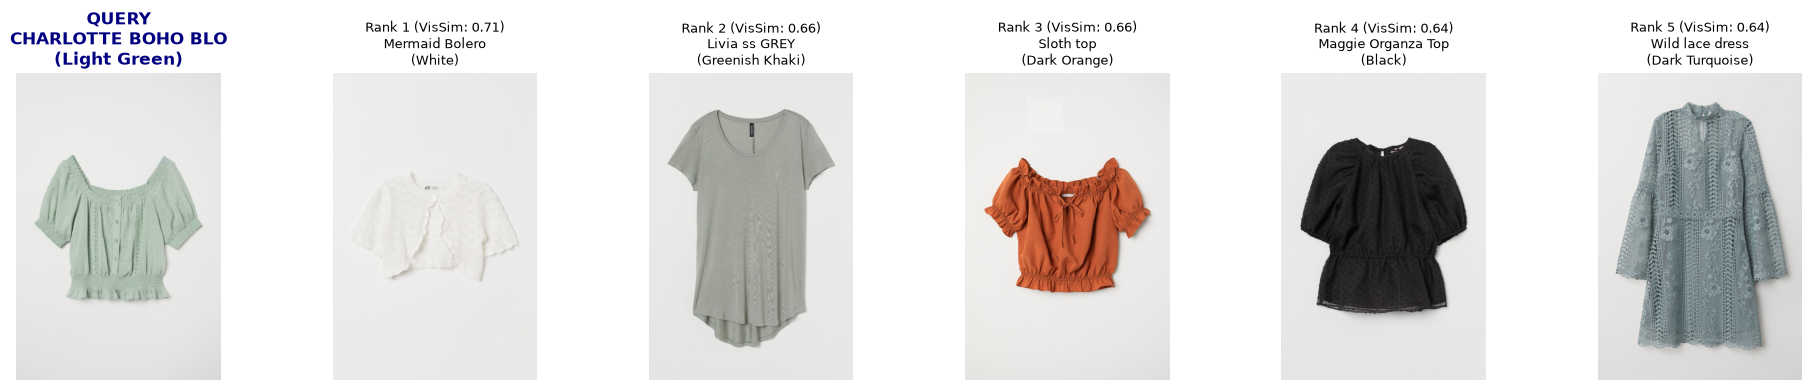

VISUAL QUERY: [0663830007] Agnes blouse
Category: Blouse | Color: Black
---------------------------------------------------------------------------


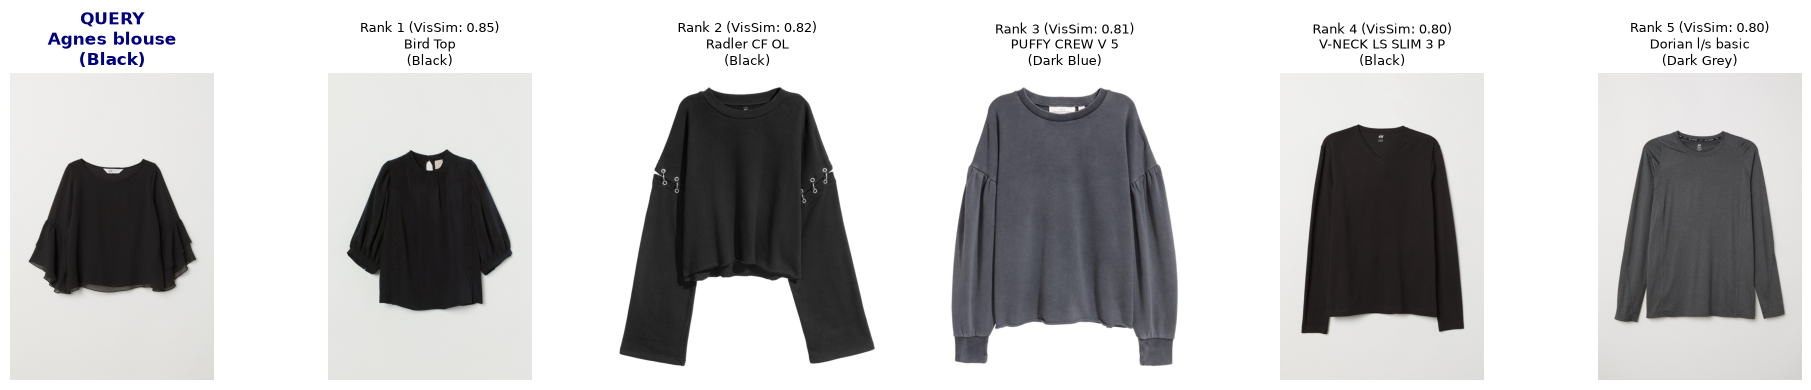

In [5]:
def display_visual_recommendations(query_aid, engine, top_k=5):
    query_meta = engine.metadata[query_aid]
    recs = engine.recommend(query_aid, top_k=top_k)
    
    print(f"VISUAL QUERY: [{query_aid}] {query_meta['prod_name']}")
    print(f"Category: {query_meta['product_type_name']} | Color: {query_meta['colour_group_name']}")
    print("-" * 75)
    
    total = 1 + len(recs)
    fig, axes = plt.subplots(1, total, figsize=(3.2 * total, 4))
    
    # Query image
    q_path = PROJECT_ROOT / query_meta["image_path"]
    with Image.open(q_path) as img:
        axes[0].imshow(img.convert("RGB"))
    axes[0].set_title(f"QUERY\n{query_meta['prod_name'][:18]}\n({query_meta['colour_group_name']})", color="navy", fontweight="bold")
    axes[0].axis("off")
    
    for i, (_, row) in enumerate(recs.iterrows()):
        ax = axes[i + 1]
        r_path = PROJECT_ROOT / row["image_path"]
        with Image.open(r_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Rank {row['rank']} (VisSim: {row['visual_similarity']:.2f})\n{row['prod_name'][:18]}\n({row['colour_group_name']})", fontsize=9)
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()
    return recs

# Test visual query 1
query_sample_1 = valid_aids[10]
recs_1 = display_visual_recommendations(query_sample_1, visual_engine, top_k=5)

# Test visual query 2
query_sample_2 = valid_aids[50]
recs_2 = display_visual_recommendations(query_sample_2, visual_engine, top_k=5)


## Section 5: Side-by-Side Comparison: Visual Similarity vs. Text TF-IDF

### What we are doing:
We compare the recommendations from our **Visual Recommender (MobileNetV2)** against our **Content Recommender (Text TF-IDF)** for the exact same query item.


In [6]:
# Load TF-IDF recommender for comparison
tfidf_matrix = sp.load_npz(PROJECT_ROOT / "artifacts" / "models" / "hm_tfidf_matrix.npz").tocsr()
art2idx = {aid: idx for idx, aid in enumerate(df_articles["article_id"])}
idx2art = {idx: aid for idx, aid in enumerate(df_articles["article_id"])}

from sklearn.metrics.pairwise import linear_kernel

def get_tfidf_recs(aid, top_k=5):
    q_idx = art2idx[aid]
    scores = linear_kernel(tfidf_matrix[q_idx], tfidf_matrix).ravel()
    scores[q_idx] = -1.0
    top_idxs = np.argsort(scores)[::-1][:top_k]
    return [idx2art[i] for i in top_idxs]

test_query = query_sample_1
vis_recs = visual_engine.recommend(test_query, top_k=5)["article_id"].tolist()
text_recs = get_tfidf_recs(test_query, top_k=5)

print(f"Comparison for Query [{test_query}] '{df_articles[df_articles['article_id']==test_query]['prod_name'].iloc[0]}':")
print(f"  Visual Nearest Neighbors: {vis_recs}")
print(f"  Text TF-IDF Neighbors:    {text_recs}")

overlap = set(vis_recs) & set(text_recs)
print(f"  Overlap between Top-5: {len(overlap)} items (Demonstrates complementary retrieval channels!)")


Comparison for Query [0602733006] 'CHARLOTTE BOHO BLOUSE SS':
  Visual Nearest Neighbors: ['0733508001', '0851680002', '0671657007', '0834348001', '0704698001']
  Text TF-IDF Neighbors:    ['0602733005', '0752379004', '0752379002', '0609598007', '0609598006']
  Overlap between Top-5: 0 items (Demonstrates complementary retrieval channels!)


## Section 6: Latency Benchmark & Validation Assertions

### What we are doing:
We benchmark retrieval speed over 100 queries and execute formal assertions.


In [7]:
# Benchmark visual retrieval latency
np.random.seed(42)
benchmark_aids = np.random.choice(valid_aids, size=100, replace=False)

latencies_ms = []
for aid in benchmark_aids:
    t0 = time.perf_counter()
    recs = visual_engine.recommend(aid, top_k=5)
    latencies_ms.append((time.perf_counter() - t0) * 1000)

lat_series = pd.Series(latencies_ms)
mean_lat = lat_series.mean()
p95_lat = lat_series.quantile(0.95)

print("=" * 60)
print("VISUAL RECOMMENDATION ENGINE BENCHMARK:")
print(f"Mean Latency:          {mean_lat:.2f} ms")
print(f"95th Percentile (p95): {p95_lat:.2f} ms")
print(f"Catalog Vector Dim:    1280 dimensions (MobileNetV2)")
print("=" * 60)

# Formal Validation Checks
assert len(recs_1) == 5, "Visual recommender failed to return 5 items"
assert query_sample_1 not in recs_1["article_id"].values, "Query item appeared in recommendations"
assert p95_lat < 15.0, f"p95 Latency ({p95_lat:.2f} ms) exceeded 15ms target!"
assert (ARTIFACTS_EMBEDDINGS_DIR / "hm_image_embeddings.npy").exists(), "Embeddings file missing"

# Save benchmark metadata
with open(ARTIFACTS_META_DIR / "visual_recommender_benchmark.json", "w", encoding="utf-8") as f:
    json.dump({
        "engine": "VisualRecommender",
        "backbone": "MobileNetV2 (1280-d)",
        "mean_latency_ms": round(float(mean_lat), 2),
        "p95_latency_ms": round(float(p95_lat), 2)
    }, f, indent=2)

print("ALL VISUAL RECOMMENDATION ASSERTIONS PASSED (100% OK)")
print("Notebook 06 complete. Ready for Notebook 07: Hybrid Recommendation.")


VISUAL RECOMMENDATION ENGINE BENCHMARK:
Mean Latency:          3.01 ms
95th Percentile (p95): 4.25 ms
Catalog Vector Dim:    1280 dimensions (MobileNetV2)
ALL VISUAL RECOMMENDATION ASSERTIONS PASSED (100% OK)
Notebook 06 complete. Ready for Notebook 07: Hybrid Recommendation.
